<a href="https://colab.research.google.com/github/judithwang021/judith-6070/blob/main/Assignments/Case_Study_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
from pathlib import Path
!pip -q install dataframe_image
import dataframe_image as dfi
from google.colab import files

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('github_token')
owner = 'judithwang021' # Replace with the GitHub repository owner
repository = 'judith-6070' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.2/48.2 MB 10.5 MB/s eta 0:00:00
Changed directoGit_HUBry to: /content/judith-6070


In [ ]:
file_path = Path("/content/judith-6070/data/data_academic_performance.xlsx")

df = pd.read_excel(file_path, sheet_name='SABER11_SABERPRO')
df.head()

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


In [ ]:
def descriptive_profile(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    return pd.Series({
        "count": series.count(),
        "mean": series.mean(),
        "median": series.median(),
        "mode": series.mode().iloc[0],
        "min": series.min(),
        "max": series.max(),
        "range": series.max() - series.min(),
        "variance": series.var(),
        "std_dev": series.std(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "skewness": series.skew()
    })

In [ ]:
print("rows: ", df.shape[0])
print("columns: ", df.shape[1])

rows:  12411
columns:  45


In [ ]:
quality_summary = pd.DataFrame({"dtype": df.dtypes.astype(str),
                               "missing": df.isna().sum(),
                               "missing_pct": df.isna().mean().mul(100).round(2),
                               "unique": df.nunique()})
quality_summary

,dtype,missing,missing_pct,unique
COD_S11,object,0,0.00,12411
GENDER,object,0,0.00,2
EDU_FATHER,object,0,0.00,12
EDU_MOTHER,object,0,0.00,12
OCC_FATHER,object,0,0.00,12
OCC_MOTHER,object,0,0.00,12
STRATUM,object,0,0.00,7
SISBEN,object,0,0.00,6
PEOPLE_HOUSE,object,0,0.00,13
Unnamed: 9,float64,12411,100.00,0


In [ ]:
df = df.dropna(axis=1, how='all')
print(df.shape)

(12411, 44)


Parental Education Influence

In [ ]:
df['EDU_FATHER'].value_counts(dropna=False)

,count
EDU_FATHER,
Complete professional education,3016
Complete Secundary,2843
Complete technique or technology,1194
Incomplete Secundary,1091
Postgraduate education,1085
Complete primary,824
Incomplete primary,735
Incomplete Professional Education,425
Not sure,407


In [ ]:
fathersum = (df.groupby('EDU_FATHER')['G_SC']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False))
fathersum = fathersum.drop(index=[0], errors='ignore')
fathersum

,count,mean
EDU_FATHER,,
Postgraduate education,1085,176.99
Complete professional education,3016,167.77
Incomplete Professional Education,425,166.92
Complete technique or technology,1194,164.03
Incomplete technical or technological,277,162.10
Not sure,407,160.29
Complete Secundary,2843,158.79
Ninguno,123,156.63
Incomplete Secundary,1091,156.54


In [ ]:
fatherpro = df.groupby('EDU_FATHER')['G_SC'].apply(descriptive_profile).unstack().sort_values('mean', ascending=False)
fatherpro = fatherpro.drop(index=[0], errors='ignore')
fatherpro.round(2)

,count,mean,median,mode,min,max,range,variance,std_dev,Q1,Q3,IQR,skewness
EDU_FATHER,,,,,,,,,,,,,
Postgraduate education,1085.00,176.99,179.00,175.00,110.00,242.00,132.00,472.37,21.73,163.00,192.00,29.00,-0.27
Complete professional education,3016.00,167.77,169.00,169.00,76.00,247.00,171.00,530.38,23.03,152.00,185.00,33.00,-0.19
Incomplete Professional Education,425.00,166.92,168.00,177.00,37.00,228.00,191.00,514.62,22.69,153.00,182.00,29.00,-0.77
Complete technique or technology,1194.00,164.03,164.00,171.00,75.00,228.00,153.00,491.30,22.17,149.00,179.75,30.75,-0.09
Incomplete technical or technological,277.00,162.10,162.00,170.00,99.00,224.00,125.00,478.79,21.88,147.00,178.00,31.00,-0.14
Not sure,407.00,160.29,159.00,143.00,102.00,236.00,134.00,526.22,22.94,143.00,177.00,34.00,0.19
Complete Secundary,2843.00,158.79,159.00,158.00,72.00,228.00,156.00,489.04,22.11,144.00,175.00,31.00,-0.08
Ninguno,123.00,156.63,159.00,142.00,77.00,220.00,143.00,537.71,23.19,140.00,173.50,33.50,-0.21
Incomplete Secundary,1091.00,156.54,157.00,161.00,76.00,220.00,144.00,472.50,21.74,141.00,172.00,31.00,-0.05


In [ ]:
dfi.export(
    fatherpro.round(2),
    'fatherpro.png',
    table_conversion='matplotlib')
files.download('fatherpro.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
mothersum = (df.groupby('EDU_MOTHER')['G_SC']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False))
mothersum = mothersum.drop(index=[0], errors='ignore')
mothersum

,count,mean
EDU_MOTHER,,
Postgraduate education,997,175.64
Complete professional education,3059,168.85
Incomplete Professional Education,502,166.69
Complete technique or technology,1495,163.24
Incomplete technical or technological,341,161.88
Not sure,179,159.41
Complete Secundary,3106,158.47
Incomplete Secundary,1056,155.67
Complete primary,713,155.34


In [ ]:
motherpro = df.groupby('EDU_MOTHER')['G_SC'].apply(descriptive_profile).unstack().sort_values('mean', ascending=False)
motherpro = motherpro.drop(index=[0], errors='ignore')
motherpro.round(2)

,count,mean,median,mode,min,max,range,variance,std_dev,Q1,Q3,IQR,skewness
EDU_MOTHER,,,,,,,,,,,,,
Postgraduate education,997.00,175.64,178.00,186.00,100.00,242.00,142.00,489.28,22.12,161.00,190.00,29.00,-0.35
Complete professional education,3059.00,168.85,170.00,177.00,91.00,246.00,155.00,528.00,22.98,153.00,185.50,32.50,-0.15
Incomplete Professional Education,502.00,166.69,168.00,159.00,37.00,243.00,206.00,525.87,22.93,153.00,183.00,30.00,-0.52
Complete technique or technology,1495.00,163.24,163.00,157.00,91.00,234.00,143.00,481.52,21.94,148.00,179.00,31.00,-0.08
Incomplete technical or technological,341.00,161.88,164.00,176.00,102.00,214.00,112.00,430.33,20.74,147.00,176.00,29.00,-0.26
Not sure,179.00,159.41,159.00,133.00,107.00,230.00,123.00,648.70,25.47,139.00,177.50,38.50,0.09
Complete Secundary,3106.00,158.47,159.00,162.00,76.00,247.00,171.00,481.78,21.95,143.00,174.00,31.00,-0.07
Incomplete Secundary,1056.00,155.67,156.00,163.00,72.00,210.00,138.00,480.87,21.93,140.00,171.25,31.25,-0.19
Complete primary,713.00,155.34,155.00,159.00,81.00,230.00,149.00,484.54,22.01,140.00,170.00,30.00,0.05


In [ ]:
dfi.export(
    motherpro.round(2),
    'motherpro.png',
    table_conversion='matplotlib')
files.download('motherpro.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
parentsum = pd.concat([fathersum.rename(
                           columns={'count': 'Father_Count', 'mean': 'Father_mean'}),
                       mothersum.rename(
                           columns={'count': 'Mother_Count', 'mean': 'Mother_mean'})],
                      axis=1)
parentsum.index.name = 'Parental education'
parentsum

,Father_Count,Father_mean,Mother_Count,Mother_mean
Parental education,,,,
Postgraduate education,1085,176.99,997,175.64
Complete professional education,3016,167.77,3059,168.85
Incomplete Professional Education,425,166.92,502,166.69
Complete technique or technology,1194,164.03,1495,163.24
Incomplete technical or technological,277,162.10,341,161.88
Not sure,407,160.29,179,159.41
Complete Secundary,2843,158.79,3106,158.47
Ninguno,123,156.63,34,149.71
Incomplete Secundary,1091,156.54,1056,155.67


In [ ]:
dfi.export(
    parentsum.round(2),
    'parentsum.png',
    table_conversion='matplotlib')

files.download('parentsum.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

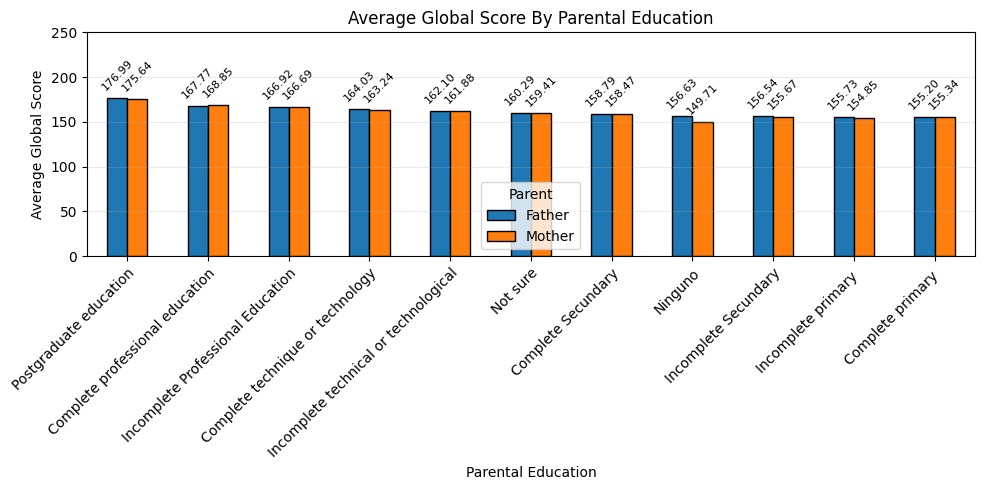

In [ ]:
plt_data = parentsum[['Father_mean', 'Mother_mean']].copy()
ax = plt_data.plot(kind="bar", figsize=(10, 5), edgecolor="black")
plt.xlabel("Parental Education")
plt.ylabel("Average Global Score")
plt.legend(title="Parent", labels=["Father", "Mother"], loc="best")
plt.title("Average Global Score By Parental Education")
plt.xticks(rotation=45, ha='right', rotation_mode='anchor')
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4, fontsize=8,
                 rotation=45)
plt.ylim(0, 250)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
fathermean = plt_data['Father_mean']
fatherdiff = pd.DataFrame(index = fathermean.index,
                          columns= fathermean.index,
                          dtype=float)
for education in fathermean.index:
    fatherdiff[education] = fathermean - fathermean[education]
display(fatherdiff.round(2))

Parental education,Postgraduate education,Complete professional education,Incomplete Professional Education,Complete technique or technology,Incomplete technical or technological,Not sure,Complete Secundary,Ninguno,Incomplete Secundary,Incomplete primary,Complete primary
Parental education,,,,,,,,,,,
Postgraduate education,0.00,9.22,10.07,12.95,14.88,16.69,18.20,20.35,20.45,21.26,21.79
Complete professional education,-9.22,0.00,0.85,3.73,5.66,7.47,8.98,11.13,11.23,12.04,12.57
Incomplete Professional Education,-10.07,-0.85,0.00,2.88,4.82,6.62,8.13,10.28,10.38,11.19,11.72
Complete technique or technology,-12.95,-3.73,-2.88,0.00,1.93,3.74,5.25,7.40,7.50,8.30,8.84
Incomplete technical or technological,-14.88,-5.66,-4.82,-1.93,0.00,1.81,3.32,5.47,5.57,6.37,6.91
Not sure,-16.69,-7.47,-6.62,-3.74,-1.81,0.00,1.51,3.66,3.76,4.57,5.10
Complete Secundary,-18.20,-8.98,-8.13,-5.25,-3.32,-1.51,0.00,2.15,2.25,3.06,3.59
Ninguno,-20.35,-11.13,-10.28,-7.40,-5.47,-3.66,-2.15,0.00,0.10,0.90,1.44
Incomplete Secundary,-20.45,-11.23,-10.38,-7.50,-5.57,-3.76,-2.25,-0.10,0.00,0.81,1.34


In [ ]:
dfi.export(
    fatherdiff.round(2),
    'fatherdiff.png',
    table_conversion='matplotlib')

files.download('fatherdiff.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
mothermean = plt_data['Mother_mean']
motherdiff = pd.DataFrame(index = mothermean.index,
                          columns= mothermean.index,
                          dtype=float)
for education in mothermean.index:
    motherdiff[education] = mothermean - mothermean[education]
display(motherdiff.round(2))

Parental education,Postgraduate education,Complete professional education,Incomplete Professional Education,Complete technique or technology,Incomplete technical or technological,Not sure,Complete Secundary,Ninguno,Incomplete Secundary,Incomplete primary,Complete primary
Parental education,,,,,,,,,,,
Postgraduate education,0.00,6.79,8.95,12.39,13.76,16.23,17.17,25.93,19.96,20.78,20.30
Complete professional education,-6.79,0.00,2.16,5.60,6.97,9.44,10.37,19.14,13.17,13.99,13.51
Incomplete Professional Education,-8.95,-2.16,0.00,3.44,4.81,7.28,8.21,16.98,11.01,11.83,11.35
Complete technique or technology,-12.39,-5.60,-3.44,0.00,1.36,3.83,4.77,13.54,7.57,8.39,7.91
Incomplete technical or technological,-13.76,-6.97,-4.81,-1.36,0.00,2.47,3.41,12.17,6.21,7.03,6.54
Not sure,-16.23,-9.44,-7.28,-3.83,-2.47,0.00,0.94,9.70,3.74,4.55,4.07
Complete Secundary,-17.17,-10.37,-8.21,-4.77,-3.41,-0.94,0.00,8.76,2.80,3.62,3.13
Ninguno,-25.93,-19.14,-16.98,-13.54,-12.17,-9.70,-8.76,0.00,-5.97,-5.15,-5.63
Incomplete Secundary,-19.96,-13.17,-11.01,-7.57,-6.21,-3.74,-2.80,5.97,0.00,0.82,0.34


In [ ]:
dfi.export(
    motherdiff.round(2),
    'motherdiff.png',
    table_conversion='matplotlib')

files.download('motherdiff.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Stratum

In [ ]:
df['STRATUM'].value_counts(dropna=False)

,count
STRATUM,
Stratum 3,4045
Stratum 2,4029
Stratum 1,1709
Stratum 4,1578
Stratum 5,633
Stratum 6,403
0,14


In [ ]:
stratum = (df.groupby('STRATUM')['G_SC']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=True))
stratum = stratum.drop(index=[0], errors='ignore')
stratum.round(2)

,count,mean
STRATUM,,
Stratum 1,1709,152.35
Stratum 2,4029,158.20
Stratum 3,4045,163.82
Stratum 4,1578,172.00
Stratum 5,633,177.39
Stratum 6,403,181.51


In [ ]:
stratumpro = df.groupby('STRATUM')['G_SC'].apply(descriptive_profile).unstack().sort_values('mean', ascending=False)
stratumpro = stratumpro.drop(index=[0], errors='ignore')
stratumpro.round(2)

,count,mean,median,mode,min,max,range,variance,std_dev,Q1,Q3,IQR,skewness
STRATUM,,,,,,,,,,,,,
Stratum 6,403.00,181.51,184.00,190.00,91.00,242.00,151.00,478.71,21.88,170.00,194.50,24.50,-0.51
Stratum 5,633.00,177.39,179.00,182.00,37.00,246.00,209.00,464.11,21.54,165.00,192.00,27.00,-0.71
Stratum 4,1578.00,172.00,174.00,175.00,91.00,243.00,152.00,460.92,21.47,158.00,188.00,30.00,-0.29
Stratum 3,4045.00,163.82,164.00,164.00,75.00,247.00,172.00,470.63,21.69,149.00,179.00,30.00,-0.08
Stratum 2,4029.00,158.20,158.00,162.00,72.00,237.00,165.00,496.31,22.28,143.00,174.00,31.00,-0.02
Stratum 1,1709.00,152.35,152.00,147.00,77.00,220.00,143.00,481.25,21.94,138.00,167.00,29.00,-0.04


In [ ]:
dfi.export(
    stratumpro.round(2),
    'stratumpro.png',
    table_conversion='matplotlib')

files.download('stratumpro.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

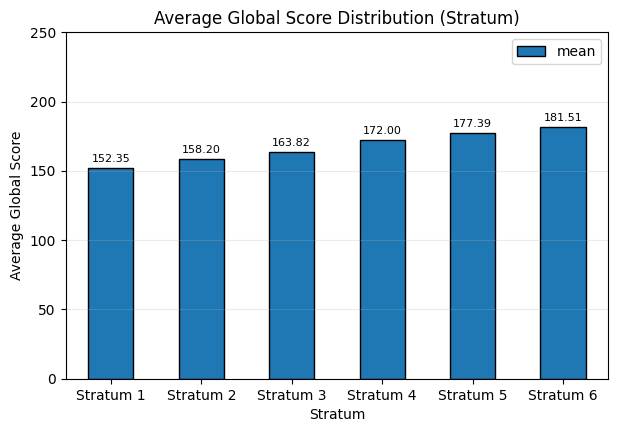

In [ ]:
stratum_plt = stratum['mean'].copy()
ax = stratum_plt.plot(kind="bar", figsize=(7, 4.5), edgecolor="black")
plt.xlabel("Stratum")
plt.ylabel("Average Global Score")
plt.legend(loc="best")
plt.title("Average Global Score Distribution (Stratum)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=8, rotation=0)
plt.ylim(0, 250)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.show()

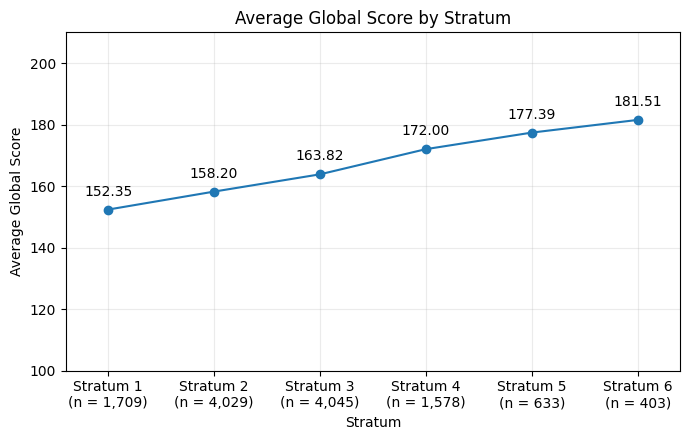

In [ ]:
stratumord = ['Stratum 1', 'Stratum 2', 'Stratum 3',
              'Stratum 4', 'Stratum 5', 'Stratum 6']
stratum_means = stratum['mean'].reindex(startumord)

ax = stratum_means.plot(kind='line',marker='o',figsize=(7, 4.5))
for i, mean_score in enumerate(stratum_means):
    ax.annotate(f'{mean_score:.2f}',
        xy=(i, mean_score),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center')

labels = []

for group in stratumord:
    count = int(stratum.loc[group, 'count'])
    labels.append(f'{group}\n(n = {count:,})')

plt.xticks(range(6), labels, rotation=0)
plt.title('Average Global Score by Stratum')
plt.xlabel('Stratum')
plt.ylabel('Average Global Score')
plt.ylim(100, 210)
plt.xlim(-0.4, 5.4)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
stratummean = stratum['mean']
stratumdiff = pd.DataFrame(index = stratummean.index,
                          columns= stratummean.index,
                          dtype=float)
for education in stratummean.index:
    stratumdiff[education] = stratummean - stratummean[education]
display(stratumdiff.round(2))

STRATUM,Stratum 1,Stratum 2,Stratum 3,Stratum 4,Stratum 5,Stratum 6
STRATUM,,,,,,
Stratum 1,0.00,-5.85,-11.46,-19.65,-25.03,-29.16
Stratum 2,5.85,0.00,-5.62,-13.80,-19.19,-23.31
Stratum 3,11.46,5.62,0.00,-8.19,-13.57,-17.70
Stratum 4,19.65,13.80,8.19,0.00,-5.38,-9.51
Stratum 5,25.03,19.19,13.57,5.38,0.00,-4.12
Stratum 6,29.16,23.31,17.70,9.51,4.12,0.00


In [ ]:
dfi.export(
    stratumdiff.round(2),
    'stratumdiff.png',
    table_conversion='matplotlib')

files.download('stratumdiff.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Gender

In [ ]:
df['GENDER'].value_counts(dropna=False)

,count
GENDER,
M,7368
F,5043


In [ ]:
gender = (df.groupby('GENDER')['G_SC']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False))
gender = gender.drop(index=[0], errors='ignore')
gender.round(2)

,count,mean
GENDER,,
M,7368,163.69
F,5043,161.28


In [ ]:
genderpro = df.groupby('GENDER')['G_SC'].apply(descriptive_profile).unstack()
genderpro.round(2)

,count,mean,median,mode,min,max,range,variance,std_dev,Q1,Q3,IQR,skewness
GENDER,,,,,,,,,,,,,
F,5043.00,161.28,162.00,158.00,76.00,242.00,166.00,498.76,22.33,146.00,177.00,31.00,-0.07
M,7368.00,163.69,164.00,159.00,37.00,247.00,210.00,556.14,23.58,147.00,180.00,33.00,-0.12


In [ ]:
dfi.export(
    genderpro.round(2),
    'genderpro.png',
    table_conversion='matplotlib')

files.download('genderpro.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

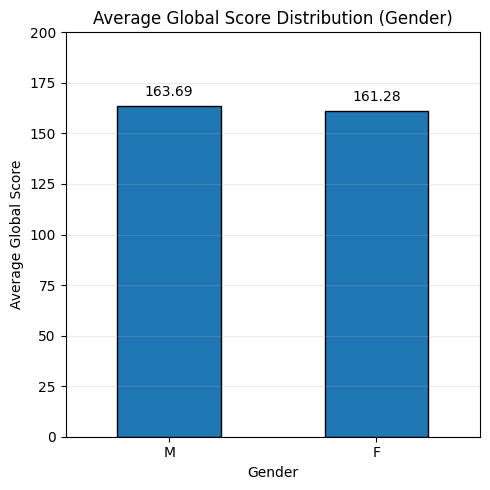

In [ ]:
ax = gender['mean'].plot(kind='bar', figsize=(5, 5), edgecolor='black')
plt.title('Average Global Score Distribution (Gender)')
plt.xlabel('Gender')
plt.ylabel('Average Global Score')
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=5)

plt.ylim(0, 200)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
genderdiff = (gender.loc['M', 'mean'] - gender.loc['F', 'mean'])
genderdiff

np.float64(2.4126177737903447)

Others

In [ ]:
programsum = (
    df.groupby('ACADEMIC_PROGRAM')['G_SC']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False))
programsum.round(2)

,count,mean
ACADEMIC_PROGRAM,,
CHEMICAL ENGINEERING,1000,176.70
CATASTRAL ENGINEERING AND GEODESY,78,174.60
ELECTRIC ENGINEERING,278,173.99
PRODUCTION ENGINEERING,60,172.90
TOPOGRAPHIC ENGINEERY,42,172.71
CONTROL ENGINEERING,20,172.15
TEXTILE ENGINEERING,1,171.00
TRANSPORTATION AND ROAD ENGINEERING,27,167.74
ELECTRONIC ENGINEERING,849,166.87


In [ ]:
subjects = ['QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO', 'FEP_PRO']
gendersub = df.groupby('GENDER')[subjects].mean()
gendersub.round(2)

,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO
GENDER,,,,,,
F,71.89,61.34,58.57,66.53,56.62,145.30
M,81.20,62.79,59.61,68.16,51.71,145.60


In [ ]:
dfi.export(
    gendersub.round(2),
    'gendersub.png',
    table_conversion='matplotlib')

files.download('gendersub.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
femalepro = (df.loc[df['GENDER'] == 'F', subjects].apply(descriptive_profile).T)
femalepro.round(2)

,count,mean,median,mode,min,max,range,variance,std_dev,Q1,Q3,IQR,skewness
QR_PRO,5043.00,71.89,78.00,100.00,1.00,100.00,99.00,581.70,24.12,56.00,92.00,36.00,-0.83
CR_PRO,5043.00,61.34,66.00,88.00,1.00,100.00,99.00,746.49,27.32,41.00,85.00,44.00,-0.48
CC_PRO,5043.00,58.57,63.00,88.00,1.00,100.00,99.00,779.34,27.92,36.00,83.00,47.00,-0.41
ENG_PRO,5043.00,66.53,72.00,92.00,1.00,100.00,99.00,612.91,24.76,51.00,87.00,36.00,-0.76
WC_PRO,5043.00,56.62,60.00,98.00,0.00,100.00,100.00,854.23,29.23,32.00,83.00,51.00,-0.28
FEP_PRO,5043.00,145.30,152.00,151.00,1.00,300.00,299.00,1544.30,39.30,126.00,172.00,46.00,-0.90


In [ ]:
malepro = (df.loc[df['GENDER'] == 'M', subjects].apply(descriptive_profile).T)
malepro.round(2)

,count,mean,median,mode,min,max,range,variance,std_dev,Q1,Q3,IQR,skewness
QR_PRO,7368.00,81.20,89.00,100.00,1.00,100.00,99.00,432.68,20.80,72.00,97.00,25.00,-1.49
CR_PRO,7368.00,62.79,69.00,95.00,1.00,100.00,99.00,777.65,27.89,42.75,87.00,44.25,-0.54
CC_PRO,7368.00,59.61,65.00,95.00,1.00,100.00,99.00,882.08,29.70,35.00,86.00,51.00,-0.43
ENG_PRO,7368.00,68.16,76.00,100.00,1.00,100.00,99.00,674.40,25.97,51.00,89.00,38.00,-0.83
WC_PRO,7368.00,51.71,53.00,0.00,0.00,100.00,100.00,921.83,30.36,25.00,79.00,54.00,-0.10
FEP_PRO,7368.00,145.60,153.00,158.00,1.00,236.00,235.00,1655.37,40.69,122.00,175.00,53.00,-0.81


In [ ]:
dfi.export(
    femalepro.round(2),
    'femalepro.png',
    table_conversion='matplotlib')

files.download('femalepro.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
dfi.export(
    malepro.round(2),
    'malepro.png',
    table_conversion='matplotlib')

files.download('malepro.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

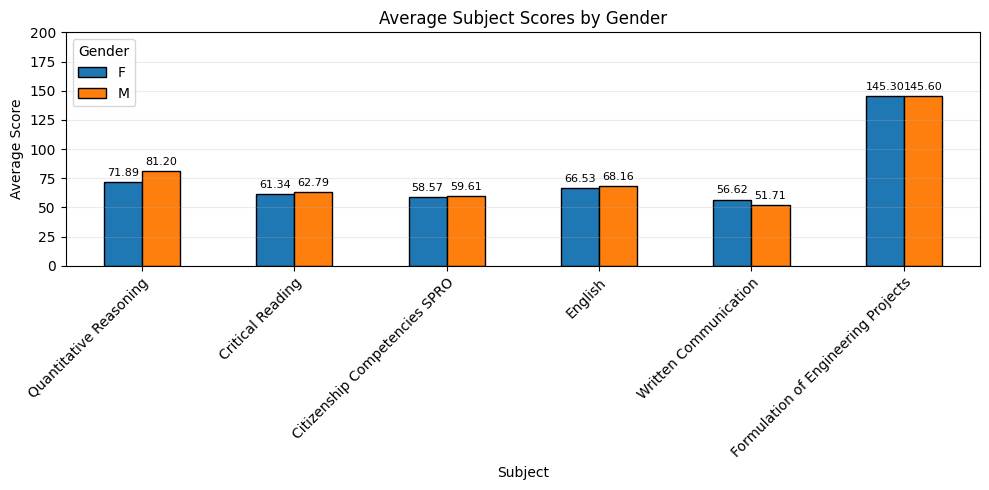

In [ ]:
plot_data = gendersub[
    ['QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO', 'FEP_PRO']].T

ax = plot_data.plot(kind='bar', figsize=(10, 5), edgecolor='black')

plt.title('Average Subject Scores by Gender')
plt.xlabel('Subject')
plt.ylabel('Average Score')
ax.set_xticklabels([
    'Quantitative Reasoning',
    'Critical Reading',
    'Citizenship Competencies SPRO',
    'English',
    'Written Communication',
    'Formulation of Engineering Projects'],
                   rotation=45, ha='right', rotation_mode='anchor')
plt.legend(title='Gender')
plt.ylim(0, 200)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

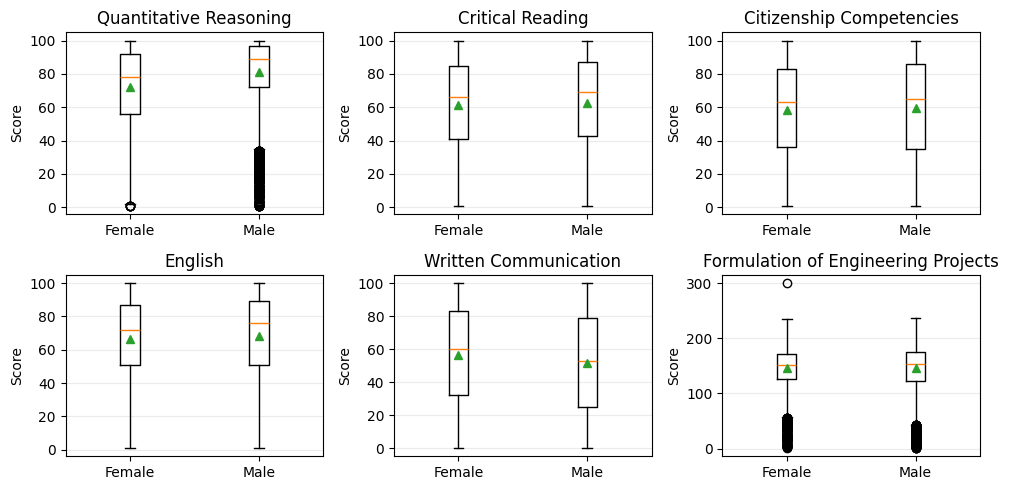

In [ ]:
subnames = {
    'QR_PRO': 'Quantitative Reasoning',
    'CR_PRO': 'Critical Reading',
    'CC_PRO': 'Citizenship Competencies',
    'ENG_PRO': 'English',
    'WC_PRO': 'Written Communication',
    'FEP_PRO': 'Formulation of Engineering Projects'}
plt.figure(figsize=(10, 5))
for i, subject in enumerate(subjects):
  plt.subplot(2, 3, i + 1)
  plt.boxplot(
    [df.loc[df['GENDER'] == 'F', subject].dropna(),
     df.loc[df['GENDER'] == 'M', subject].dropna()],
    tick_labels=['Female', 'Male'],
    showmeans=True)
  plt.ylabel("Score")
  plt.title(subnames[subject])
  plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()